# AICS-202 | Laboratory 03
## Training Data Poisoning and Dataset Integrity
Course module: 3 | Suggested duration: 4 hours

**Objective:** measure how deliberately corrupted labels in a local training dataset affect a supervised model. This lab never changes external datasets or services.

**Scope:** simple random label corruption is an introductory poisoning simulation, not a realistic targeted backdoor.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

SEED = 42
np.random.seed(SEED)
digits = load_digits()
X = digits.data.astype(float) / 16.0
y = digits.target.astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y
)

def build_model(train_features, train_labels):
    model = LogisticRegression(max_iter=600, random_state=SEED)
    model.fit(train_features, train_labels)
    return model

model = build_model(X_train, y_train)
print('Dataset:', X.shape, '| Train:', len(X_train), '| Test:', len(X_test))
print('Clean test accuracy:', round(accuracy_score(y_test, model.predict(X_test)), 4))

Dataset: (1797, 64) | Train: 1347 | Test: 450
Clean test accuracy: 0.9622


Corruption 0%: 0 labels changed | Clean test accuracy 0.962
Corruption 5%: 67 labels changed | Clean test accuracy 0.960
Corruption 10%: 135 labels changed | Clean test accuracy 0.958
Corruption 20%: 269 labels changed | Clean test accuracy 0.933


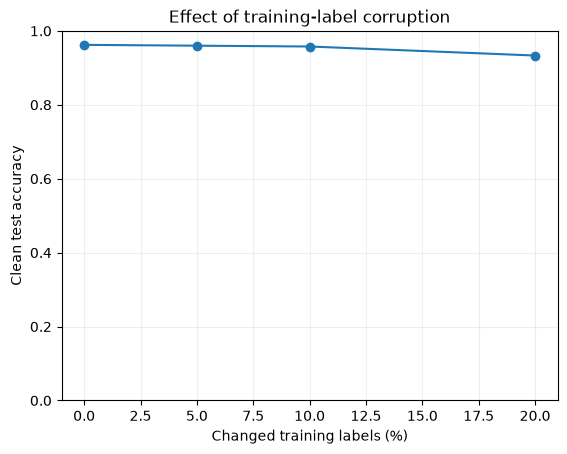

In [2]:
from sklearn.metrics import confusion_matrix
rng = np.random.default_rng(2026)
corruption_levels = [0.00, 0.05, 0.10, 0.20]
records = []
for fraction in corruption_levels:
    labels_changed = y_train.copy()
    n = round(len(labels_changed)*fraction)
    selected = rng.choice(len(labels_changed), size=n, replace=False)
    # Replace with a *different* label; this simulates integrity compromise.
    labels_changed[selected] = (labels_changed[selected] + rng.integers(1, 10, size=n)) % 10
    tested_model = build_model(X_train, labels_changed)
    accuracy = accuracy_score(y_test, tested_model.predict(X_test))
    records.append((fraction, n, accuracy))
    print(f'Corruption {fraction:.0%}: {n} labels changed | Clean test accuracy {accuracy:.3f}')
plt.plot([r[0]*100 for r in records], [r[2] for r in records], 'o-')
plt.xlabel('Changed training labels (%)'); plt.ylabel('Clean test accuracy')
plt.title('Effect of training-label corruption');plt.ylim(0,1);plt.grid(alpha=.2);plt.show()

### Part B - Create a data integrity checklist
Prepare a controls table for dataset provenance, cryptographic hashes, label audits, role-restricted writes, staged approval, and anomaly review.

**Student exercises:**
- Explain why training data is a security asset.
- Compare control results and explain any non-monotonic accuracy changes.
- Propose three technical and two procedural safeguards.

**Deliverables:** plot, results table, explanation and a signed-off integrity checklist for this hypothetical dataset.

In [3]:
import hashlib
def sha(arr):
    return hashlib.sha256(np.ascontiguousarray(arr).tobytes()).hexdigest()

reference = sha(y_train)
print("Reference hash of training labels:", reference[:16], "...")
print("Unchanged copy matches:", sha(y_train.copy()) == reference)

tampered = y_train.copy()
tampered[0] = (tampered[0] + 1) % 10
print("After changing one label, hash:", sha(tampered)[:16], "...")
print("Tampered copy matches:", sha(tampered) == reference)

Reference hash of training labels: ee47679cf3fee774 ...
Unchanged copy matches: True
After changing one label, hash: de9550f10dd9892e ...
Tampered copy matches: False


## Part B: Data Integrity

### Results
| Corrupted training labels | Labels changed | Clean test accuracy | Test images correct (of 450) |
|---|---|---|---|
| 0% | 0 | 0.962 | 433 |
| 5% | 67 | 0.960 | 432 |
| 10% | 135 | 0.958 | 431 |
| 20% | 269 | 0.933 | 420 |

Only the training labels were changed. The 450 test labels stayed untouched, so every row is measured against the same answer key.

### Why training data is a security asset
A model only learns what its data teaches it, so whoever controls the data controls what the model does. Tampering with labels is hard to spot because the model still trains normally and can still look fine on standard tests. Training data can also hold private information, which adds a confidentiality risk.

### Comparing the results
Accuracy never rose as corruption increased, so I saw no non-monotonic change in this run. The loss was tiny up to 10% (one and two test images) and clearer at 20% (13 images fewer than the clean model). With one seed and one split, I would not read the small differences as a real trend. One possible reason for the model's tolerance is that random wrong labels are spread across all digits and partly cancel out, but I did not test this. This was random corruption, not a targeted attack, so it says little about what a deliberate attacker could do.

### Hash check
A SHA-256 hash of the 1,347 training labels matched an unchanged copy, and changing a single label produced a different hash (E03_hash_check). A hash shows that something changed, but not what or who, and the reference hash has to be stored where an attacker cannot also edit it.

### Safeguards
Technical:
1. A hash manifest for the dataset, verified before every training run.
2. Role-based write access to the data and labels, with every change logged.
3. Automated checks before training: label distribution, comparison with the previous version, and accuracy against a held-out reference.

Procedural:
1. Staged approval, so data is prepared, reviewed and signed off before it is used for training.
2. A provenance register and change-control process recording the source, owner and approver of every dataset version.

### Integrity checklist (hypothetical dataset)
| Control | Check | Evidence | Status |
|---|---|---|---|
| Dataset provenance | Source, owner and permitted use recorded | Source register | Not assessed |
| Cryptographic hashes | Hash manifest created and verified | Verification log | Demonstrated in this lab |
| Label audit | Independent sample check of labels | Audit report | Not assessed |
| Role-restricted writes | Only approved roles can edit data | Permission records | Not assessed |
| Staged approval | Separate preparation, review, sign-off | Sign-off record | Not assessed |
| Anomaly review | Accuracy and label-distribution drift monitored | Monitoring log | Not assessed |

Prepared by: Janet Anya Okewu-Ihezie, 13 November 2026
Independent reviewer sign-off: pending

## Lab 03 Analysis

### What I did
I took the baseline model from Lab 01 and trained it on training sets where a share of the labels had been replaced with a different digit. The corruption levels were 0%, 5%, 10% and 20% of the 1,347 training records (0, 67, 135 and 269 labels changed). Each time I measured accuracy on the same 450 test images, whose labels were never touched (E03_corruption_results, E03_corruption_chart).

### What I measured
Clean test accuracy was 0.962, 0.960, 0.958 and 0.933 for the four levels. In test images that is 433, 432, 431 and 420 correct out of 450. The 5% and 10% levels cost only one and two images, which is too small a difference to call a trend from one seed and one split. The 20% level lost 13 images, about 2.9 percentage points, which is a clearer drop but still from a single run.

### What this does and does not show
The model tolerated random label corruption fairly well in this experiment. One possible reason is that wrong labels spread across all ten digits and partly cancel out, but I did not test that. I would not conclude that poisoning is harmless. Random label noise is not a targeted attack. An attacker who chooses which labels to change, or who plants a backdoor trigger, could do much more damage with fewer changes. This lab does not simulate that.

### Why the test labels must stay unchanged
The test set is the fixed answer key that every model is marked against. If I changed it, or let training data leak into it, the accuracy numbers would no longer be comparable between the four runs. That is why only the training labels were altered.

### Hypothetical incident: forensic chronology
Suppose an auditor finds that an upstream label-approval step was bypassed for part of the training data. Altered labels could enter the pipeline at these points:
1. **Collection or labelling:** a compromised annotator or tool assigns wrong labels.
2. **Storage and transfer:** the dataset file is edited after approval.
3. **Preparation:** a script or merge step overwrites labels.
4. **Training:** the model is trained on the changed data and passed to deployment.

The six questions from the worksheet, for my experiment:
* **What changed?** A set share of training labels, replaced at random with a different digit.
* **What did not change?** The test images and test labels.
* **How would it be detected?** A hash mismatch against the reference manifest, a gap in the approval history, or an unexplained fall in accuracy. In my hash check, changing one label out of 1,347 gave a different SHA-256 hash (E03_hash_check).
* **What was the measured impact?** Accuracy of 0.933 at 20% corruption, against 0.962 for the clean model.
* **What remains unknown?** Whether a targeted attack would do more harm, and how this transfers to other models or real systems.
* **How should the organisation respond?** Contain by stopping use of the affected model, compare dataset versions, have an independent person review the labels, roll back to the last verified version, retrain and retest, and record a sign-off.

### Escalation path for unexplained accuracy loss
1. **Monitoring** flags a fall in accuracy or a shift in label distribution.
2. **Data owner** checks recent dataset changes and the hash manifest.
3. **Security team** is notified if a hash mismatch or a bypassed approval is found, and investigates who changed what.
4. **Containment decision:** the model owner decides whether to pause the model or roll back.
5. **Independent review and retest** before any sign-off to return to use.

### Limits of this experiment
It used one seed, one split, one model, tiny 8×8 images, and random corruption only. A hash shows that something changed but not what or who, and it only helps if the reference hash is stored where an attacker cannot edit it. I assessed only the hash control in practice. The other controls in my Part B checklist are marked "Not assessed".